# XAUUSD LSTM: trejdovi 1:2 (uprošćena verzija)
Ista logika kao originalni notebook: triple-barrier labele, LSTM (3 klase), HistGB poređenje,
trend pravilo (pomeraj ±pipsa + EMA), meta model (smer od trenda, LSTM/stabla/ansambl) i backtest.

In [1]:
import os, re, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score)
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

## 0. Podešavanja

In [2]:
TIMEFRAME    = "1h"                       # "1h" ili "1d"
DATA_DIR     = Path(os.environ.get("XAU_DATA_DIR", next(        # automatski nalazi dataset
    (p for p in map(Path, ["./dataset", "./code/dataset"]) if (p / "XAUUSD60.csv").exists()), "./dataset"))).expanduser()
TRAIN_START  = pd.Timestamp("2016-01-03")
TEST_START   = pd.Timestamp("2026-01-03")  # pre = train, od ovog datuma = test
BACKCANDLES  = {"1h": 24, "1d": 20}[TIMEFRAME]
SPREAD_USD   = 0.25                       # spread po round-trip-u, USD/oz
SEED         = 42
RR, SL_ATR_MULT = 2.0, 1.0                # TP = 2R, R = 1 x ATR14
HORIZON      = {"1h": 24, "1d": 10}[TIMEFRAME]
RISK_PCT     = 1.0
Q            = 0.80                       # percentil pragova na validaciji

# ★★★ TREND — OVDE MENJAŠ ★★★
TREND_PIPS        = 250                   # pomeraj od ovoliko pipsa gore = LONG, dole = SHORT
PIP_SIZE_USD      = 0.10                  # 1 pip zlata u USD
TREND_LOOKBACK    = {"1h": 24, "1d": 5}[TIMEFRAME]
USE_TREND_FILTER  = True
TREND_EMA_LEN     = 200                   # 0 = bez EMA potvrde
AUTO_SELECT_TREND = True                  # bira parametre samo na train godinama
MIN_TREND_TRADES  = {"1h": 500, "1d": 200}[TIMEFRAME]
META_QUANTILE     = 0.50                  # bolja polovina trend-setup-a
# ★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

## 1. Učitavanje podataka

In [3]:
def find_file(key):
    """Nalazi CSV po delu imena (ignorise razmake, '-', '_' i velika slova)."""
    norm = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
    for p in sorted(DATA_DIR.glob("*.csv")):
        if norm(key) in norm(p.name):
            return p
    raise FileNotFoundError(f"Ne nalazim fajl koji sadrzi '{key}' u {DATA_DIR}")

def load_mt5(key):
    """MT5 export: tab, bez header-a: Date Open High Low Close Volume."""
    df = pd.read_csv(find_file(key), sep="\t", header=None, usecols=range(5),
                     names=["Date", "Open", "High", "Low", "Close"])
    df["Date"] = pd.to_datetime(df["Date"], format="mixed")
    df = df.set_index("Date").sort_index()
    return df[~df.index.duplicated(keep="last")]

def load_investing(key):
    """Investing.com export -> serija 'Price'."""
    df = pd.read_csv(find_file(key), encoding="utf-8-sig", thousands=",")
    df.columns = [c.strip().strip('"') for c in df.columns]
    s = df.assign(Date=pd.to_datetime(df["Date"], format="%m/%d/%Y")).set_index("Date")["Price"]
    s = s.sort_index().astype(float)
    return s[~s.index.duplicated(keep="last")]

def load_fred(key, monthly=False):
    df = pd.read_csv(find_file(key), names=["Date", "Value"], header=0, parse_dates=["Date"])
    s = df.set_index("Date")["Value"].sort_index().astype(float)
    return s.set_axis(s.index.to_period("M")) if monthly else s

gold = load_mt5("XAUUSD60" if TIMEFRAME == "1h" else "XAUUSD1440")
print("Zlato:", gold.shape, "|", gold.index.min(), "->", gold.index.max())

Zlato: (100000, 4) | 2010-02-15 01:00:00 -> 2026-11-04 07:00:00


## 2. Feature-i

In [4]:
ema = lambda s, n: s.ewm(span=n, adjust=False).mean()

def rsi(c, n=14):
    d = c.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + up / dn.replace(0, np.nan))

def true_range(x):
    c = x["Close"]
    return pd.concat([x["High"] - x["Low"], (x["High"] - c.shift()).abs(),
                      (x["Low"] - c.shift()).abs()], axis=1).max(axis=1)

def technical(x):
    c = x["Close"]
    f = pd.DataFrame(index=x.index)
    macd = ema(c, 12) - ema(c, 26)
    f["RSI"] = rsi(c)
    f["MACD_line"] = macd / c
    f["MACD_hist"] = (macd - ema(macd, 9)) / c
    e = {n: ema(c, n) for n in (20, 50, 100)}
    for n in e:
        f[f"EMA{n}_ratio"] = c / e[n] - 1
    f["EMA20_vs_EMA100"] = e[20] / e[100] - 1
    s = {n: c.rolling(n).mean() for n in (50, 200)}
    for n in s:
        f[f"SMA{n}_ratio"] = c / s[n] - 1
    f["SMA50_vs_SMA200"] = s[50] / s[200] - 1
    mid, sd = c.rolling(20).mean(), c.rolling(20).std()
    f["BOLL_pos"] = (c - mid) / (2 * sd.replace(0, np.nan))
    f["ATR_norm"] = true_range(x).rolling(14).mean() / c
    for h in (1, 3, 6, 12, 24):
        f[f"ret_{h}"] = c.pct_change(h)
    for w in (12, 24, 72):
        f[f"vol_{w}"] = c.pct_change().rolling(w).std()
    f["dow"] = x.index.dayofweek
    return f

def intraday(x):
    """Pozicija u tekucem danu + sesija (1h)."""
    c, h = x["Close"], x.index.hour
    day = pd.Index(x.index.date)
    hi, lo = x["High"].groupby(day).cummax(), x["Low"].groupby(day).cummin()
    prev_close = c.groupby(day).last()
    prev_close.index = pd.to_datetime(prev_close.index)
    f = pd.DataFrame(index=x.index)
    f["day_range_pos"] = (c - lo) / (hi - lo).replace(0, np.nan)
    f["dist_day_high"] = (hi - c) / c
    f["dist_day_low"] = (c - lo) / c
    f["gap_vs_prev_close"] = c / x.index.normalize().map(prev_close.shift(1)).values - 1
    f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    f["sess_asia"] = ((h >= 0) & (h <= 7)).astype(int)
    f["sess_london"] = ((h >= 8) & (h <= 12)).astype(int)
    f["sess_ny"] = ((h >= 13) & (h <= 20)).astype(int)
    return f

def daily_feat(s, p):
    m, sd = s.rolling(20).mean(), s.rolling(20).std()
    return pd.DataFrame({f"{p}_ret1d": s.pct_change(), f"{p}_ret5d": s.pct_change(5),
                         f"{p}_z20": (s - m) / sd.replace(0, np.nan), f"{p}_sma20_ratio": s / m - 1},
                        index=s.index)

def attach_daily(bar_index, feat):
    """Dnevni podatak dana D vazi tek od D+1 (bez curenja)."""
    end = max(feat.index.max(), bar_index.max().normalize())
    cal = feat.reindex(pd.date_range(feat.index.min(), end, freq="D")).ffill().shift(1)
    out = cal.reindex(bar_index.normalize())
    out.index = bar_index
    return out

def monthly_feat(s, p, end):
    """MoM + diff, kasnjenje 2 meseca (konzervativno)."""
    s = s.interpolate(limit_area="inside")
    d = pd.DataFrame({f"{p}_mom": s.pct_change(), f"{p}_diff": s.diff()})
    d = d.reindex(pd.period_range(d.index.min(), max(d.index.max(), end), freq="M"))
    return d.shift(2)

def attach_monthly(bar_index, feat):
    out = feat.reindex(bar_index.to_period("M"))
    out.index = bar_index
    return out

def span(s):
    lo, hi = s.index.min(), s.index.max()
    if isinstance(lo, pd.Period):
        lo, hi = lo.start_time, hi.end_time
    return pd.Timestamp(lo), pd.Timestamp(hi)

In [5]:
parts = [technical(gold)]
if TIMEFRAME == "1h":
    parts.append(intraday(gold))
    xd = load_mt5("XAUUSD1440")["Close"]
    fd = pd.DataFrame({"xau1d_ret": xd.pct_change(), "xau1d_ret5": xd.pct_change(5),
                       "xau1d_sma20_ratio": xd / xd.rolling(20).mean() - 1,
                       "xau1d_sma50_ratio": xd / xd.rolling(50).mean() - 1,
                       "xau1d_vol20": xd.pct_change().rolling(20).std(),
                       "xau1d_hi20_dist": xd / xd.rolling(20).max() - 1}, index=xd.index)
    parts.append(attach_daily(gold.index, fd))

# Eksterni faktori: serija se koristi samo ako pokriva pocetak train perioda (+31 dan tolerancije)
daily = {"dxy": load_investing("us_dollar_index"), "vix": load_investing("volatility_index"),
         "wti": load_investing("wti"), "us10y": load_fred("US10YN"),
         "btc": load_mt5("BTCUSD1440")["Close"]}
monthly = {"cpi": load_fred("CPI", monthly=True), "ppi": load_fred("PPI", monthly=True),
           "nfp": load_fred("NFP", monthly=True)}
min_start = TRAIN_START + pd.Timedelta(days=31)
usable = lambda s: not (span(s)[1] < TRAIN_START or span(s)[0] > min_start)

used, skipped = [], []
for name, s in daily.items():
    if usable(s):
        parts.append(attach_daily(gold.index, daily_feat(s, name))); used.append(name)
    else:
        skipped.append(name)
for name, s in monthly.items():
    if usable(s):
        parts.append(attach_monthly(gold.index, monthly_feat(s, name, gold.index.max().to_period("M"))))
        used.append(name)
    else:
        skipped.append(name)

features = pd.concat(parts, axis=1)
features = features.fillna({c: 0.0 for c in features if c.startswith("btc_")})
print("Korisceni eksterni faktori:", used)
print("Preskoceni zbog nedovoljne istorije:", skipped)
print("FEATURES:", features.shape, "|", features.index.min(), "->", features.index.max())

Korisceni eksterni faktori: ['dxy', 'vix', 'us10y', 'cpi', 'ppi', 'nfp']
Preskoceni zbog nedovoljne istorije: ['wti', 'btc']
FEATURES: (100000, 54) | 2010-02-15 01:00:00 -> 2026-11-04 07:00:00


## 3. Trejd 1:2 i target (triple barrier)
Ulaz = open sledece sveće. SL = 1R, TP = 2R (R = SL_ATR_MULT x ATR14). Ako su SL i TP u istoj
sveći, računa se SL (konzervativno). Bez pogotka za HORIZON sveća → izlaz po close.

In [6]:
def triple_barrier(ohlc, atr, k, rr, H):
    o, h, l, c = (ohlc[x].values.astype(float) for x in ("Open", "High", "Low", "Close"))
    m = len(ohlc) - H
    Hw = sliding_window_view(h, H)[1:m + 1]
    Lw = sliding_window_view(l, H)[1:m + 1]
    c_last, e = c[H:H + m], o[1:m + 1]
    R = atr.values[:m] * k
    out = pd.DataFrame({"entry": e, "R": R}, index=ohlc.index[:m])
    big = H + 1
    for side, d in (("long", 1), ("short", -1)):
        tp, sl = e + d * rr * R, e - d * R
        hit_tp = (Hw >= tp[:, None]) if d == 1 else (Lw <= tp[:, None])
        hit_sl = (Lw <= sl[:, None]) if d == 1 else (Hw >= sl[:, None])
        i_tp = np.where(hit_tp.any(1), hit_tp.argmax(1), big)
        i_sl = np.where(hit_sl.any(1), hit_sl.argmax(1), big)
        win = i_tp < i_sl
        loss = (i_sl < big) & (i_sl <= i_tp)
        out[f"{side}_win"] = win
        out[f"{side}_res"] = np.where(win, rr, np.where(loss, -1.0, d * (c_last - e) / R))
        out[f"{side}_exit"] = np.arange(m) + 1 + np.where(win, i_tp, np.where(loss, i_sl, H - 1))
    out["label"] = np.select([out["long_win"], out["short_win"]], [2, 1], default=0).astype(float)
    out.loc[out["R"].isna(), "label"] = np.nan
    return out

tr_range = true_range(gold)
labels = triple_barrier(gold, tr_range.rolling(14).mean(), SL_ATR_MULT, RR, HORIZON)

In [7]:
data = features.join(labels["label"].rename("Target"))
data = data[data.index >= TRAIN_START].replace([np.inf, -np.inf], np.nan).dropna()
data["Target"] = data["Target"].astype(int)
lab = labels.reindex(data.index)

counts = data["Target"].value_counts().reindex([0, 1, 2], fill_value=0)
print("DATA:", data.shape, "|", data.index.min(), "->", data.index.max())
print(pd.DataFrame({"broj": counts.values, "udeo": (counts / counts.sum()).round(3).values},
                   index=["0: bez trejda", "1: short TP", "2: long TP"]))
print(f"Break-even win rate 1:{RR:.0f} = {1 / (1 + RR):.1%} | prosecan R u USD: {lab['R'].mean():.2f}")

DATA: (62657, 55) | 2016-04-01 00:00:00 -> 2026-11-03 06:00:00
                broj   udeo
0: bez trejda  22540  0.360
1: short TP    19518  0.312
2: long TP     20599  0.329
Break-even win rate 1:2 = 33.3% | prosecan R u USD: 6.26


## 4. Train / test, skaliranje, sekvence

In [8]:
train_mask = data.index < TEST_START
feat_cols = [c for c in data.columns if c != "Target"]
scaler = StandardScaler().fit(data.loc[train_mask, feat_cols])          # fit samo na train
X_all = np.clip(scaler.transform(data[feat_cols]), -5, 5).astype(np.float32)
y_all, times = data["Target"].to_numpy(int), data.index
n_feat = X_all.shape[1]

W = sliding_window_view(X_all, (BACKCANDLES, n_feat))[:, 0]           # (n, B, p)
end = np.arange(BACKCANDLES - 1, len(X_all))
y_seq, t_seq = y_all[end], times[end]

tr_pos = np.where(t_seq < TEST_START)[0][:-HORIZON]                    # embargo
te_pos = np.where(t_seq >= TEST_START)[0]
n_val = max(int(len(tr_pos) * 0.10), 50)
val_pos = tr_pos[-n_val:]
fit_pos = tr_pos[:-(n_val + max(BACKCANDLES, HORIZON))]

X_train, y_train = W[fit_pos].astype(np.float32), y_seq[fit_pos]
X_val, y_val = W[val_pos].astype(np.float32), y_seq[val_pos]
X_test, y_test = W[te_pos].astype(np.float32), y_seq[te_pos]
test_index = t_seq[te_pos]
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape,
      "| Test period:", test_index[0], "->", test_index[-1])

Train: (51882, 24, 54) | Val: (5767, 24, 54) | Test: (4937, 24, 54) | Test period: 2026-01-04 23:00:00 -> 2026-11-03 06:00:00


## 5. LSTM (3 klase)

In [9]:
tf.keras.utils.set_random_seed(SEED)
inp = Input(shape=(BACKCANDLES, n_feat))
x = LSTM({"1h": 64, "1d": 32}[TIMEFRAME])(inp)
x = Dropout(0.3)(x)
x = Dense(32, activation="relu")(x)
x = Dropout(0.2)(x)
model = Model(inp, Dense(3, activation="softmax")(x))
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cw = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)))
model.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size={"1h": 256, "1d": 64}[TIMEFRAME],
          epochs=30, shuffle=True, class_weight=cw, verbose=2,
          callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
                     ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)])

proba_train = model.predict(X_train, batch_size=1024, verbose=0)
proba_val = model.predict(X_val, batch_size=1024, verbose=0)
proba_test = model.predict(X_test, batch_size=1024, verbose=0)
pred_test = proba_test.argmax(1)
lbl = ["0 bez trejda", "1 short TP", "2 long TP"]
print(f"Test accuracy: {accuracy_score(y_test, pred_test):.4%} | balanced: "
      f"{balanced_accuracy_score(y_test, pred_test):.4%} | naivna osnova: "
      f"{np.bincount(y_test, minlength=3).max() / len(y_test):.4%}")
print(classification_report(y_test, pred_test, target_names=lbl, zero_division=0))

Test accuracy: 32.8134% | balanced: 32.5639% | naivna osnova: 35.1023%
              precision    recall  f1-score   support

0 bez trejda       0.34      0.62      0.44      1676
  1 short TP       0.33      0.18      0.23      1733
   2 long TP       0.30      0.18      0.23      1528

    accuracy                           0.33      4937
   macro avg       0.32      0.33      0.30      4937
weighted avg       0.32      0.33      0.30      4937



## 6. Signali i backtest 1:2
LONG ako je P(2) >= prag i > P(1); SHORT analogno. Pragovi = percentil Q na VALIDACIJI.
Jedan trejd u isto vreme. Spread se preračunava u R.

In [10]:
def make_signals(p, t_long, t_short):
    s = np.zeros(len(p), dtype=int)
    s[(p[:, 2] >= t_long) & (p[:, 2] > p[:, 1])] = 1
    s[(p[:, 1] >= t_short) & (p[:, 1] > p[:, 2])] = -1
    return s

def backtest(sig):
    """sig: Series (vreme odluke -> 1 / -1 / 0). Trejd se otvara na sledecoj sveci."""
    pos = gold.index.get_indexer(sig.index)
    rows, busy = [], -1
    for tm, s, p in zip(sig.index, sig.values, pos):
        if s == 0 or p < busy:
            continue
        side = "long" if s == 1 else "short"
        res, R = float(lab.at[tm, f"{side}_res"]), float(lab.at[tm, "R"])
        rows.append((tm, side, res, res - SPREAD_USD / R))
        busy = int(lab.at[tm, f"{side}_exit"])
    return pd.DataFrame(rows, columns=["time", "side", "R_gross", "R_net"]).set_index("time")

def rr_stats(tr, rr=RR, risk_pct=RISK_PCT):
    if tr.empty:
        return {"trejdova": 0}
    eq = tr["R_net"].cumsum()
    wins, losses = tr.loc[tr["R_net"] > 0, "R_net"].sum(), -tr.loc[tr["R_net"] < 0, "R_net"].sum()
    tp = tr["R_gross"] >= rr - 1e-9
    sl = tr["R_gross"] <= -1 + 1e-9
    return {
        "trejdova": len(tr),
        "long / short": f"{(tr['side'] == 'long').sum()} / {(tr['side'] == 'short').sum()}",
        "TP pogodjen": f"{tp.mean():.1%}",
        "SL pogodjen": f"{sl.mean():.1%}",
        "istek vremena": f"{(~tp & ~sl).mean():.1%}",
        "prosek R po trejdu (neto)": round(tr["R_net"].mean(), 3),
        "ukupno R (neto)": round(tr["R_net"].sum(), 1),
        "profit factor": round(wins / losses, 2) if losses > 0 else np.nan,
        "max drawdown (R)": round((eq - eq.cummax()).min(), 1),
        f"prinos pri {risk_pct:g}% rizika": f"{(1 + risk_pct / 100 * tr['R_net']).prod() - 1:.1%}",
    }

thr_long, thr_short = np.quantile(proba_val[:, 2], Q), np.quantile(proba_val[:, 1], Q)
print(f"Pragovi iz validacije (p{Q:.0%}): LONG P2 >= {thr_long:.4f} | SHORT P1 >= {thr_short:.4f}")

sig_test = make_signals(proba_test, thr_long, thr_short)
sig_s = pd.Series(sig_test, index=test_index)
print(sig_s.map({1: "LONG", -1: "SHORT", 0: "bez trejda"}).value_counts().to_dict())

tr_lstm = backtest(sig_s)
tr_long = backtest(pd.Series(1, index=test_index))
tr_short = backtest(pd.Series(-1, index=test_index))
pd.DataFrame({"LSTM signali": rr_stats(tr_lstm), "Osnova: uvek LONG": rr_stats(tr_long),
              "Osnova: uvek SHORT": rr_stats(tr_short)})

,LSTM signali,Osnova: uvek LONG,Osnova: uvek SHORT
trejdova,364,874,845
long / short,188 / 176,874 / 0,0 / 845
TP pogodjen,33.0%,30.5%,34.4%
SL pogodjen,66.5%,67.8%,64.3%
istek vremena,0.5%,1.6%,1.3%
prosek R po trejdu (neto),-0.016,-0.075,0.039
ukupno R (neto),-5.8,-65.8,33.1
profit factor,0.98,0.89,1.06
max drawdown (R),-24.9,-104.0,-43.5
prinos pri 1% rizika,-8.9%,-52.3%,27.9%


In [11]:
# Osetljivost na prag (samo informativno)
rows = []
for q in (0.50, 0.60, 0.70, 0.80, 0.90, 0.95):
    tl, ts = np.quantile(proba_val[:, 2], q), np.quantile(proba_val[:, 1], q)
    out = {"percentil": q}
    for nm, p, idx in (("val", proba_val, t_seq[val_pos]), ("test", proba_test, test_index)):
        tr = backtest(pd.Series(make_signals(p, tl, ts), index=idx))
        out[f"{nm}: trejdova"] = len(tr)
        out[f"{nm}: R/trejd"] = round(tr["R_net"].mean(), 3) if len(tr) else np.nan
    rows.append(out)
pd.DataFrame(rows).set_index("percentil")

,val: trejdova,val: R/trejd,test: trejdova,test: R/trejd
percentil,,,,
0.50,956,0.027,674,0.002
0.60,867,0.027,567,-0.031
0.70,745,0.047,483,0.005
0.80,585,0.059,364,-0.016
0.90,350,-0.004,220,-0.052
0.95,173,0.055,123,0.014


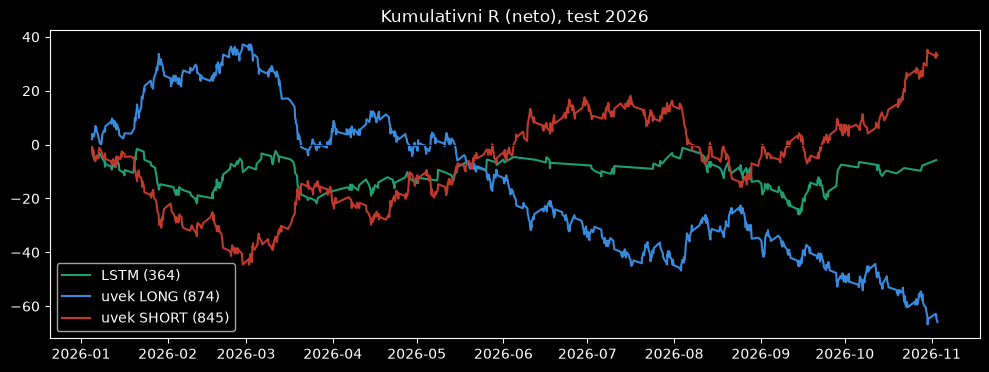

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
for tr, name, col in ((tr_lstm, "LSTM", "#1D9E75"), (tr_long, "uvek LONG", "#378ADD"),
                      (tr_short, "uvek SHORT", "#C0392B")):
    ax.plot(tr.index, tr["R_net"].cumsum(), label=f"{name} ({len(tr)})", color=col)
ax.axhline(0, color="k", lw=0.6); ax.set_title("Kumulativni R (neto), test 2026"); ax.legend(); plt.show()

## 7. Poređenje: stabla odluke (HistGB) i ansambl

In [13]:
trees = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, l2_regularization=1.0,
                                       early_stopping=False, class_weight="balanced", random_state=SEED)
Xt = X_all[end]                       # stabla gledaju poslednju sveću (kao u originalu)
trees.fit(Xt[fit_pos], y_train)
tp_val, tp_test = trees.predict_proba(Xt[val_pos]), trees.predict_proba(Xt[te_pos])
tpred_test = tp_test.argmax(1)
print(f"Stabla — test accuracy {accuracy_score(y_test, tpred_test):.4%} | balanced "
      f"{balanced_accuracy_score(y_test, tpred_test):.4%}")

sig_tree = make_signals(tp_test, np.quantile(tp_val[:, 2], Q), np.quantile(tp_val[:, 1], Q))
tr_tree = backtest(pd.Series(sig_tree, index=test_index))

p_ens_val, p_ens_test = (proba_val + tp_val) / 2, (proba_test + tp_test) / 2
sig_ens = make_signals(p_ens_test, np.quantile(p_ens_val[:, 2], Q), np.quantile(p_ens_val[:, 1], Q))
tr_ens = backtest(pd.Series(sig_ens, index=test_index))
print("Slaganje LSTM i stabala u predikciji klase: {:.1%}".format((pred_test == tpred_test).mean()))
pd.DataFrame({"LSTM": rr_stats(tr_lstm), "Stabla odluke": rr_stats(tr_tree), "Ansambl": rr_stats(tr_ens),
              "Uvek LONG": rr_stats(tr_long), "Uvek SHORT": rr_stats(tr_short)})

,LSTM,Stabla odluke,Ansambl,Uvek LONG,Uvek SHORT
trejdova,364,491,411,874,845
long / short,188 / 176,304 / 187,223 / 188,874 / 0,0 / 845
TP pogodjen,33.0%,31.2%,33.3%,30.5%,34.4%
SL pogodjen,66.5%,68.0%,65.7%,67.8%,64.3%
istek vremena,0.5%,0.8%,1.0%,1.6%,1.3%
prosek R po trejdu (neto),-0.016,-0.062,0.003,-0.075,0.039
ukupno R (neto),-5.8,-30.5,1.1,-65.8,33.1
profit factor,0.98,0.91,1.0,0.89,1.06
max drawdown (R),-24.9,-45.6,-26.1,-104.0,-43.5
prinos pri 1% rizika,-8.9%,-29.7%,-2.9%,-52.3%,27.9%


## 8. Trend pravilo: pomeraj ±TREND_PIPS + EMA potvrda
LONG: cena porasla >= TREND_PIPS u TREND_LOOKBACK sveća **i** iznad EMA. SHORT: analogno. Inače neutralan.
Ako je AUTO_SELECT_TREND=True, parametri se biraju iz mreže SAMO na train godinama (2016–2025).

In [14]:
def trend_state(close, lookback, pips, ema_len):
    mv = (close - close.shift(lookback)) / PIP_SIZE_USD
    t = pd.Series(0, index=close.index)
    t[mv >= pips] = 1
    t[mv <= -pips] = -1
    if ema_len:
        e = ema(close, ema_len)
        t[(t == 1) & (close < e)] = 0
        t[(t == -1) & (close > e)] = 0
    return t

train_idx = data.index[train_mask]
grid = []
for lb, pips, el in itertools.product({"1h": [12, 24, 48, 96], "1d": [3, 5, 10, 20]}[TIMEFRAME],
                                      [150, 250, 400], [0, 50, 200]):
    t = trend_state(gold["Close"], lb, pips, el).reindex(train_idx).fillna(0).astype(int)
    tr = backtest(pd.Series(t.values, index=train_idx))
    if len(tr) < MIN_TREND_TRADES:
        continue
    by_year = tr["R_net"].groupby(tr.index.year).mean()
    grid.append(dict(lookback=lb, pips=pips, ema=el, trades=len(tr), R_per_trade=tr["R_net"].mean(),
                     years_positive=int((by_year > 0).sum()), years=len(by_year), worst_year=by_year.min()))
grid_df = pd.DataFrame(grid)
grid_df["pos_share"] = grid_df["years_positive"] / grid_df["years"]
grid_df = grid_df.sort_values(["pos_share", "R_per_trade"], ascending=False).reset_index(drop=True)

if AUTO_SELECT_TREND and len(grid_df):
    b = grid_df.iloc[0]
    TREND_LOOKBACK, TREND_PIPS, TREND_EMA_LEN = int(b["lookback"]), int(b["pips"]), int(b["ema"])
print("AUTO" if AUTO_SELECT_TREND else "RUCNO", f"(samo train 2016-2025) LOOKBACK={TREND_LOOKBACK} | PIPS={TREND_PIPS} | EMA={TREND_EMA_LEN} | kandidata={len(grid_df)}")
grid_df.head(10).round(3)

,lookback,pips,ema,trades,R_per_trade,years_positive,years,worst_year,pos_share
0,12,250,50,1105,0.028,8,11,-0.562,0.727
1,12,250,0,1149,0.024,7,11,-0.562,0.636
2,24,400,200,630,0.040,5,9,-1.017,0.556
3,48,400,0,1393,0.028,5,9,-0.239,0.556
4,48,400,200,1325,0.024,5,9,-0.239,0.556
5,48,400,50,1360,0.005,5,9,-0.239,0.556
6,12,250,200,943,0.044,6,11,-1.016,0.545
7,12,150,200,2111,0.023,6,11,-1.016,0.545
8,12,150,50,2500,0.012,6,11,-0.489,0.545
9,12,150,0,2630,-0.004,6,11,-0.489,0.545


In [15]:
trend = trend_state(gold["Close"], TREND_LOOKBACK, TREND_PIPS, TREND_EMA_LEN)
trend_d = trend.reindex(data.index).fillna(0).astype(int)
trend_move = (gold["Close"] - gold["Close"].shift(TREND_LOOKBACK)) / PIP_SIZE_USD

tr_rule_train = backtest(pd.Series(trend_d.reindex(train_idx).values, index=train_idx))
tr_rule_test = backtest(pd.Series(trend_d.reindex(test_index).values, index=test_index))
by_year = tr_rule_train["R_net"].groupby(tr_rule_train.index.year).agg(["count", "mean"]).round(3)
print("Trend po godinama (train, R/trejd):", by_year["mean"].to_dict())

def apply_trend_filter(sig, t):
    out = np.array(sig, copy=True)
    out[(out == 1) & (t != 1)] = 0
    out[(out == -1) & (t != -1)] = 0
    return out

trend_test = trend_d.reindex(test_index).values
flt = (lambda s: apply_trend_filter(s, trend_test)) if USE_TREND_FILTER else (lambda s: np.array(s))
tr_lstm_f = backtest(pd.Series(flt(sig_test), index=test_index))
tr_tree_f = backtest(pd.Series(flt(sig_tree), index=test_index))
print(f"LSTM signala pre filtera: {(sig_test != 0).sum()} -> posle: {(flt(sig_test) != 0).sum()}")
pd.DataFrame({"Samo trend": rr_stats(tr_rule_test), "LSTM (bez filtera)": rr_stats(tr_lstm),
              "LSTM + trend filter": rr_stats(tr_lstm_f), "Stabla + trend filter": rr_stats(tr_tree_f),
              "Uvek LONG": rr_stats(tr_long), "Uvek SHORT": rr_stats(tr_short)})

,Samo trend,LSTM (bez filtera),LSTM + trend filter,Stabla + trend filter,Uvek LONG,Uvek SHORT
trejdova,620,364,62,103,874,845
long / short,282 / 338,188 / 176,27 / 35,66 / 37,874 / 0,0 / 845
TP pogodjen,34.5%,33.0%,43.5%,30.1%,30.5%,34.4%
SL pogodjen,64.5%,66.5%,56.5%,68.9%,67.8%,64.3%
istek vremena,1.0%,0.5%,0.0%,1.0%,1.6%,1.3%
prosek R po trejdu (neto),0.033,-0.016,0.292,-0.083,-0.075,0.039
ukupno R (neto),20.7,-5.8,18.1,-8.5,-65.8,33.1
profit factor,1.05,0.98,1.51,0.88,0.89,1.06
max drawdown (R),-23.9,-24.9,-8.2,-12.3,-104.0,-43.5
prinos pri 1% rizika,15.5%,-8.9%,19.0%,-9.1%,-52.3%,27.9%


## 9. Meta model: trend bira SMER, model bira DA LI da se uzme trejd
Pitanje: da li će trejd u smeru trenda pogoditi TP (+2R) pre SL (−1R)? Prag na validaciji.

In [16]:
trend_vals = trend_d.values
move = np.clip(trend_move.reindex(data.index).fillna(0).values / TREND_PIPS, -3, 3)

def meta_sets(pos):
    e = end[pos]
    tr = trend_vals[e]
    keep = tr != 0
    pos, tr, e = pos[keep], tr[keep], e[keep]
    y = (((tr == 1) & (y_seq[pos] == 2)) | ((tr == -1) & (y_seq[pos] == 1))).astype(int)
    tab = np.c_[X_all[e], tr, move[e]].astype(np.float32)
    return dict(pos=pos, trend=tr, y=y, tab=tab, idx=t_seq[pos])

M_fit, M_val, M_test = meta_sets(fit_pos), meta_sets(val_pos), meta_sets(te_pos)
for nm, M in (("fit", M_fit), ("val", M_val), ("test", M_test)):
    print(f"{nm:5s}: {len(M['y']):5d} trend-sveca | TP u {M['y'].mean():.1%}")

meta_trees = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, max_depth=3, l2_regularization=2.0,
                                            min_samples_leaf=40, early_stopping=False,
                                            class_weight="balanced", random_state=SEED)
meta_trees.fit(M_fit["tab"], M_fit["y"])
p_tree = {k: meta_trees.predict_proba(M["tab"])[:, 1] for k, M in (("val", M_val), ("test", M_test))}

def meta_seq(M):
    ch = np.repeat(M["trend"][:, None, None].astype(np.float32), BACKCANDLES, axis=1)
    return np.concatenate([W[M["pos"]].astype(np.float32), ch], axis=2)

S_fit, S_val, S_test = meta_seq(M_fit), meta_seq(M_val), meta_seq(M_test)
cw_m = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=M_fit["y"])))

def build_meta_lstm(units):
    inp = Input(shape=(BACKCANDLES, n_feat + 1))
    x = LSTM(units)(inp)
    x = Dropout(0.4)(x)
    x = Dense(16, activation="relu")(x)
    x = Dropout(0.3)(x)
    m = Model(inp, Dense(1, activation="sigmoid")(x))
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return m

pl_val, pl_test = [], []
for s in range(3):                                   # prosek 3 seed-a
    tf.keras.utils.set_random_seed(SEED + s)
    mm = build_meta_lstm({"1h": 32, "1d": 16}[TIMEFRAME])
    mm.fit(S_fit, M_fit["y"], validation_data=(S_val, M_val["y"]), epochs=40,
           batch_size={"1h": 128, "1d": 32}[TIMEFRAME], class_weight=cw_m, verbose=0,
           callbacks=[EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
    pl_val.append(mm.predict(S_val, verbose=0).ravel())
    pl_test.append(mm.predict(S_test, verbose=0).ravel())
p_lstm = {"val": np.mean(pl_val, axis=0), "test": np.mean(pl_test, axis=0)}
p_ens = {k: (p_tree[k] + p_lstm[k]) / 2 for k in ("val", "test")}

auc = lambda y, p: roc_auc_score(y, p) if len(np.unique(y)) > 1 else float("nan")
print(pd.DataFrame({"AUC val": [auc(M_val["y"], p["val"]) for p in (p_tree, p_lstm, p_ens)],
                    "AUC test": [auc(M_test["y"], p["test"]) for p in (p_tree, p_lstm, p_ens)]},
                   index=["Meta stabla", "Meta LSTM", "Meta ansambl"]).round(4))

              AUC val  AUC test
Meta stabla    0.5412    0.4968
Meta LSTM      0.5622    0.4966
Meta ansambl   0.5598    0.4980


In [17]:
variants = {"Meta: stabla": p_tree, "Meta: LSTM": p_lstm, "Meta: ansambl": p_ens}
trades, takes = {}, {}
for name, p in variants.items():
    thr = np.quantile(p["val"], META_QUANTILE)                         # prag iz VALIDACIJE
    take = p["test"] >= thr
    trades[name] = backtest(pd.Series(np.where(take, M_test["trend"], 0), index=M_test["idx"]))
    takes[name] = take
    print(f"{name:14s} prag {thr:.3f} | prihvaceno {take.sum()}/{len(take)} | "
          f"win rate prihvacenih {M_test['y'][take].mean():.1%} (svih {M_test['y'].mean():.1%})")

stats = {"Samo trend (svi setup-i)": rr_stats(tr_rule_test)}
stats.update({k: rr_stats(v) for k, v in trades.items()})
stats.update({"Uvek LONG": rr_stats(tr_long), "Uvek SHORT": rr_stats(tr_short)})
pd.DataFrame(stats)

,Samo trend (svi setup-i),Meta: stabla,Meta: LSTM,Meta: ansambl,Uvek LONG,Uvek SHORT
trejdova,620,392,291,338,874,845
long / short,282 / 338,166 / 226,137 / 154,148 / 190,874 / 0,0 / 845
TP pogodjen,34.5%,34.2%,35.7%,35.2%,30.5%,34.4%
SL pogodjen,64.5%,64.5%,64.3%,64.2%,67.8%,64.3%
istek vremena,1.0%,1.3%,0.0%,0.6%,1.6%,1.3%
prosek R po trejdu (neto),0.033,0.026,0.058,0.05,-0.075,0.039
ukupno R (neto),20.7,10.4,17.0,17.1,-65.8,33.1
profit factor,1.05,1.04,1.09,1.08,0.89,1.06
max drawdown (R),-23.9,-21.7,-33.0,-23.1,-104.0,-43.5
prinos pri 1% rizika,15.5%,6.6%,15.0%,14.6%,-52.3%,27.9%


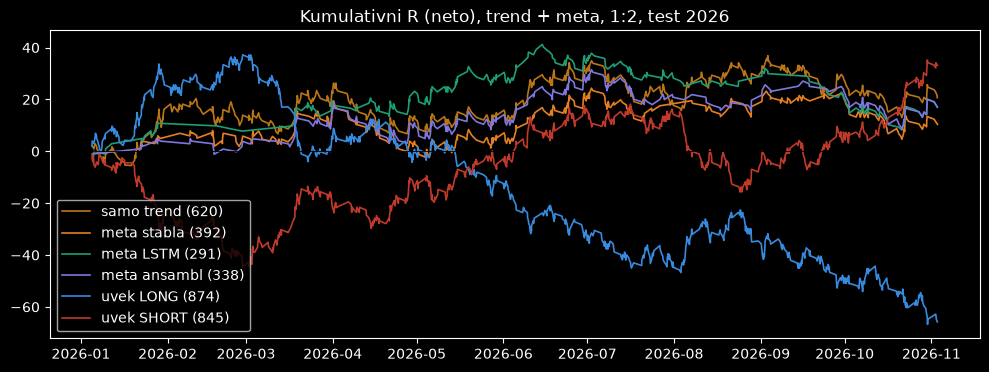

In [18]:
take = takes["Meta: ansambl"]
print(classification_report(M_test["y"], take.astype(int), target_names=["odbijen", "prihvacen"],
                            zero_division=0))

fig, ax = plt.subplots(figsize=(12, 4))
for tr, name, col in ((tr_rule_test, "samo trend", "#BA7517"), (trades["Meta: stabla"], "meta stabla", "#E67E22"),
                      (trades["Meta: LSTM"], "meta LSTM", "#1D9E75"), (trades["Meta: ansambl"], "meta ansambl", "#7F77DD"),
                      (tr_long, "uvek LONG", "#378ADD"), (tr_short, "uvek SHORT", "#C0392B")):
    if len(tr):
        ax.plot(tr.index, tr["R_net"].cumsum(), label=f"{name} ({len(tr)})", color=col, lw=1.2)
ax.axhline(0, color="k", lw=0.6); ax.set_title(f"Kumulativni R (neto), trend + meta, 1:{RR:.0f}, test 2026")
ax.legend(); plt.show()

In [19]:
# Osetljivost na META_QUANTILE (samo informativno)
rows = []
for q in (0.0, 0.3, 0.5, 0.7, 0.85):
    thr = np.quantile(p_ens["val"], q)
    out = {"META_QUANTILE": q}
    for nm, M, p in (("val", M_val, p_ens["val"]), ("test", M_test, p_ens["test"])):
        tr = backtest(pd.Series(np.where(p >= thr, M["trend"], 0), index=M["idx"]))
        out[f"{nm}: trejdova"] = len(tr)
        out[f"{nm}: R/trejd"] = round(tr["R_net"].mean(), 3) if len(tr) else np.nan
    rows.append(out)
pd.DataFrame(rows).set_index("META_QUANTILE")

,val: trejdova,val: R/trejd,test: trejdova,test: R/trejd
META_QUANTILE,,,,
0.00,456,0.048,620,0.033
0.30,353,0.067,476,0.046
0.50,252,0.103,338,0.050
0.70,158,0.293,215,0.088
0.85,86,0.375,136,0.110


In [20]:
# Poslednji signali (ansambl): smer = trend, ocena = verovatnoca da trejd pogodi TP
pd.DataFrame({
    "trend": np.where(M_test["trend"] == 1, "LONG", "SHORT"),
    "meta_verovatnoca_TP": p_ens["test"].round(3),
    "odluka": np.where(take, np.where(M_test["trend"] == 1, "LONG", "SHORT"), "NEMA TREJDA"),
    "stvarno (TP?)": np.where(M_test["y"] == 1, "da", "ne"),
}, index=M_test["idx"]).tail(15)

,trend,meta_verovatnoca_TP,odluka,stvarno (TP?)
Date,,,,
2026-11-01 23:00:00,SHORT,0.403,NEMA TREJDA,ne
2026-11-02 00:00:00,SHORT,0.425,SHORT,ne
2026-11-02 01:00:00,SHORT,0.444,SHORT,ne
2026-11-02 02:00:00,SHORT,0.426,SHORT,ne
2026-11-02 14:00:00,LONG,0.588,LONG,ne
2026-11-02 15:00:00,LONG,0.559,LONG,ne
2026-11-02 16:00:00,LONG,0.559,LONG,ne
2026-11-02 17:00:00,LONG,0.542,LONG,ne
2026-11-02 18:00:00,LONG,0.534,LONG,ne


## 10. Čuvanje

In [21]:
out_dir = Path("rezultati_notebook_rr"); out_dir.mkdir(exist_ok=True)
model.save(out_dir / f"lstm_rr12_{TIMEFRAME}.keras")
joblib.dump({"scaler": scaler, "feature_cols": feat_cols, "backcandles": BACKCANDLES, "rr": RR,
             "sl_atr_mult": SL_ATR_MULT, "horizon": HORIZON,
             "trend": dict(pips=TREND_PIPS, lookback=TREND_LOOKBACK, ema=TREND_EMA_LEN, pip_size=PIP_SIZE_USD),
             "thr_long": float(thr_long), "thr_short": float(thr_short)},
            out_dir / f"lstm_rr12_{TIMEFRAME}_meta.joblib")
tr_lstm.to_csv(out_dir / f"trejdovi_lstm_{TIMEFRAME}_test.csv")
print("Sacuvano u:", out_dir.resolve())

Sacuvano u: /Users/djordjeradosavljevic/Downloads/fax/diplomski/code/rezultati_notebook_rr
